## Name: Harsh Sambare
## Class: C-C1
## Roll No: 8
## ML EXPERIMENT 6 (ANN)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report


In [ ]:
df=pd.read_csv("seeds_new.csv")

In [ ]:
df=df.dropna(axis=1,how="all")

In [ ]:
df=df.loc[:, ~df.columns.str.startswith("Unnamed")]

In [ ]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [ ]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3,NaN,NaN
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3,NaN,NaN
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3,NaN,NaN
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3,NaN,NaN
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3,NaN,NaN


In [ ]:
df.shape

(210, 10)

In [ ]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)', 'Unnamed: 8', 'Unnamed: 9'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
 8   Unnamed: 8               2 non-null      object 
 9   Unnamed: 9               1 non-null      object 
dtypes: float64(7), int64(1), object(2)
memory usage: 16.5+ KB


In [ ]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [ ]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0
Unnamed: 8,208
Unnamed: 9,209


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
Area,193
Perimeter,170
Compactness,186
Length of kernel,188
Width of kernel,184
Asymmetry coefficient,207
Length of kernel groove,148
"Class (1, 2, 3)",3
Unnamed: 8,1
Unnamed: 9,1


In [ ]:
df['Class (1, 2, 3)'].value_counts()

,count
"Class (1, 2, 3)",
1,70
2,70
3,70


In [ ]:
df.corr(numeric_only=True)

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
Area,1.000000,0.994341,0.608288,0.949985,0.970771,-0.229572,0.863693,-0.346058
Perimeter,0.994341,1.000000,0.529244,0.972422,0.944829,-0.217340,0.890784,-0.327900
Compactness,0.608288,0.529244,1.000000,0.367915,0.761635,-0.331471,0.226825,-0.531007
Length of kernel,0.949985,0.972422,0.367915,1.000000,0.860415,-0.171562,0.932806,-0.257269
Width of kernel,0.970771,0.944829,0.761635,0.860415,1.000000,-0.258037,0.749131,-0.423463
Asymmetry coefficient,-0.229572,-0.217340,-0.331471,-0.171562,-0.258037,1.000000,-0.011079,0.577273
Length of kernel groove,0.863693,0.890784,0.226825,0.932806,0.749131,-0.011079,1.000000,0.024301
"Class (1, 2, 3)",-0.346058,-0.327900,-0.531007,-0.257269,-0.423463,0.577273,0.024301,1.000000


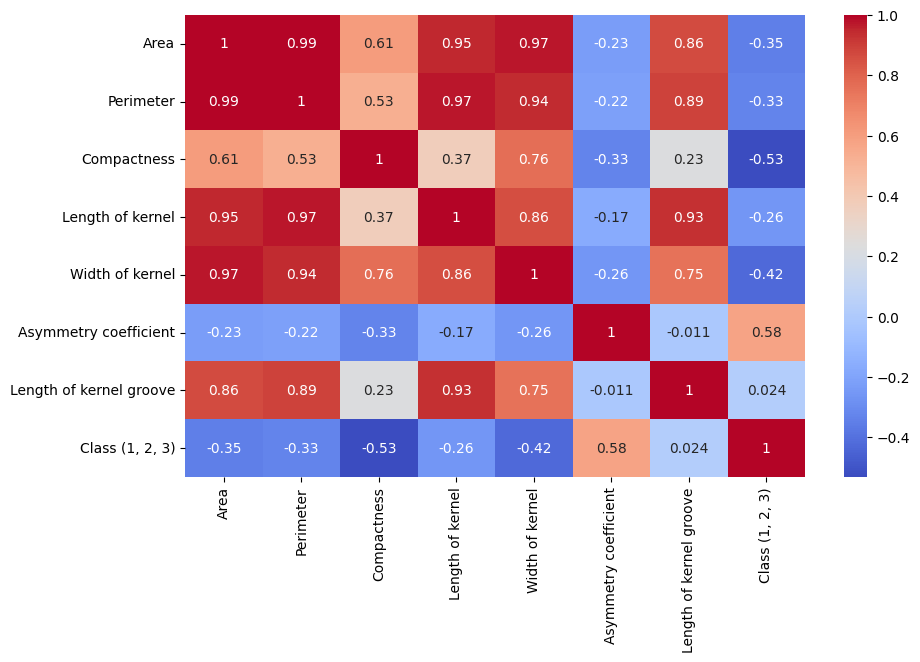

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.show()

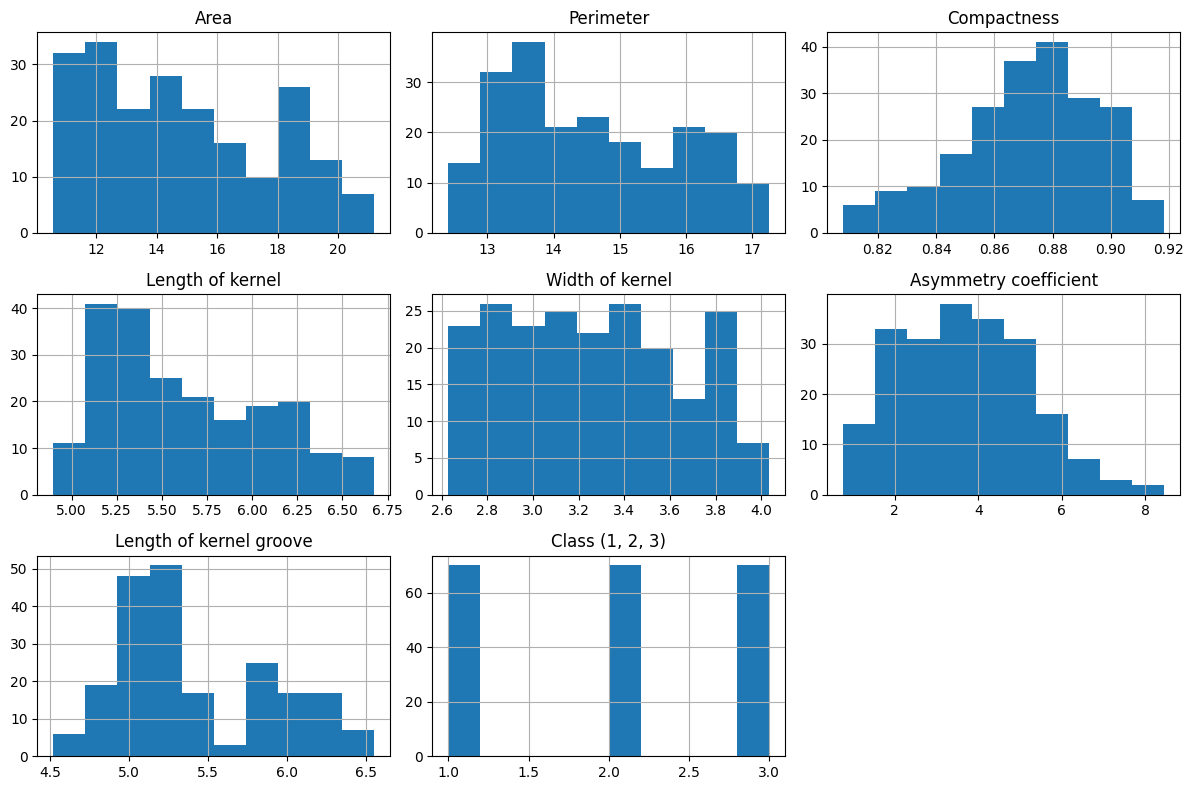

In [ ]:
df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

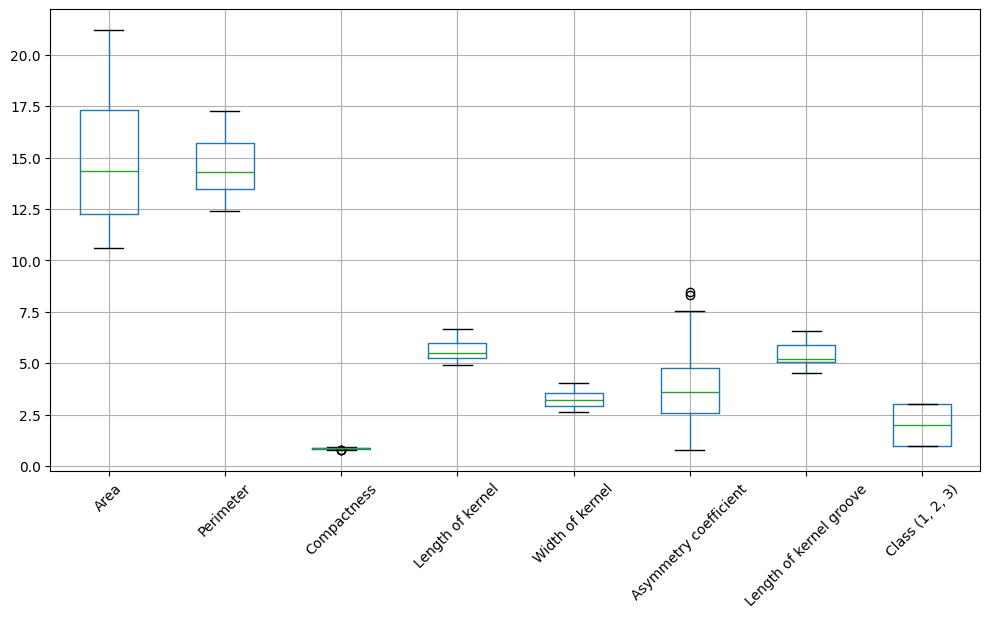

In [ ]:

df.boxplot(figsize=(12,6))
plt.xticks(rotation=45)
plt.show()

In [ ]:
X=df.drop('Class (1, 2, 3)',axis=1)
y_original=df["Class (1, 2, 3)"]
print(X.shape)
print(y_original.shape)

(210, 7)
(210,)


In [ ]:
y=y_original-1
print(sorted(y_original.unique()))
print(sorted(y.unique()))

[np.int64(1), np.int64(2), np.int64(3)]
[np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [ ]:
scaler.fit_transform(X_test)

array([[-0.52991291, -0.49623599, -0.27871655, -0.28725548, -0.68950684,
        -1.89773913, -0.63786437],
       [-1.17566801, -1.13903806, -1.3157494 , -1.08016108, -1.23712694,
         0.29497821, -0.74893692],
       [ 1.63968755,  1.68929104,  0.22486319,  1.68850928,  1.44414504,
        -0.56016822,  1.60143767],
       [-0.66658066, -0.82898059,  1.01010617, -1.11265721, -0.22454638,
        -0.64523847, -1.08612146],
       [-1.12441761, -1.22222421, -0.18909643, -1.25347378, -1.01239605,
        -0.7264996 , -1.52842824],
       [-1.20300156, -1.07853904, -2.02417513, -0.72920286, -1.46444094,
         1.24979649, -0.3145639 ],
       [-0.31124452, -0.32986369,  0.28460994, -0.45623536, -0.22454638,
        -1.45023154, -0.82629102],
       [-0.8613322 , -0.84410535, -0.63292941, -0.75086695, -0.85999234,
         0.64287742, -0.43555364],
       [ 0.5907626 ,  0.58518396,  0.65162568,  0.64430027,  0.6795434 ,
        -1.19057684,  0.30823578],
       [-0.65633058, -0.7155

In [ ]:
print(X_train[:5])

[[-1.05385596 -1.04083248 -0.88880831 -0.86174582 -1.13018592  1.03548208
  -0.22342116]
 [ 1.52927104  1.5495697   0.46355711  1.60878046  1.46287997 -0.1265987
   1.69031688]
 [-0.86392015 -0.87893234 -0.40975723 -0.96258363 -0.73186961  1.222849
  -0.76198116]
 [-0.17669786 -0.14652697  0.0862514  -0.16046471 -0.29345435 -1.48822186
  -0.23781017]
 [-1.2230715  -1.31837557 -0.4648693  -1.34301718 -1.10612655 -0.21453263
  -0.84831521]]


In [ ]:
model=Sequential([
Input(shape=(7,)),
Dense(64, activation="relu"),
Dense(16, activation="relu"),
Dense(8, activation="softmax")
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,688 (6.59 KB)

 Trainable params: 1,688 (6.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop=EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [ ]:
history=model.fit(
    X_train,y_train,
    validation_data=(X_test,y_test),
    batch_size=32,
    validation_split=0.2,
    epochs=100,
    callbacks=[early_stop]
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.4226 - loss: 1.9893 - val_accuracy: 0.5952 - val_loss: 1.8425
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5714 - loss: 1.8040 - val_accuracy: 0.6905 - val_loss: 1.6702
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6429 - loss: 1.6433 - val_accuracy: 0.7143 - val_loss: 1.5113
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6429 - loss: 1.4982 - val_accuracy: 0.7381 - val_loss: 1.3633
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6488 - loss: 1.3588 - val_accuracy: 0.7381 - val_loss: 1.2231
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6726 - loss: 1.2302 - val_accuracy: 0.7381 - val_loss: 1.0870
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7381 - loss: 1.1067 - val_accuracy: 0.8095 - val_loss: 0.9631
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7976 - loss: 0.9923 - val_accuracy: 0.8095 - val_loss:

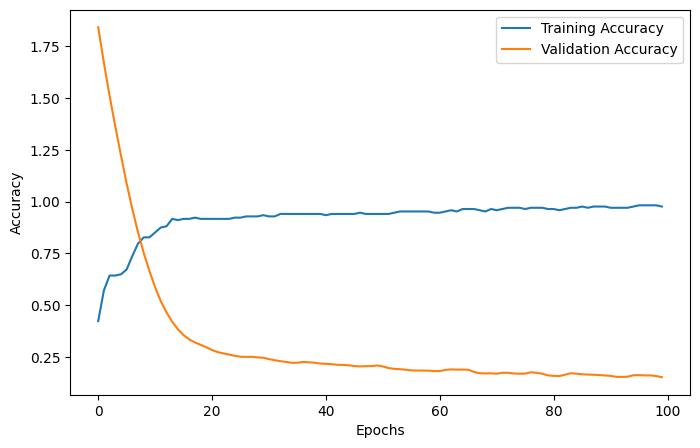

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.plot(history.history['val_loss'],label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

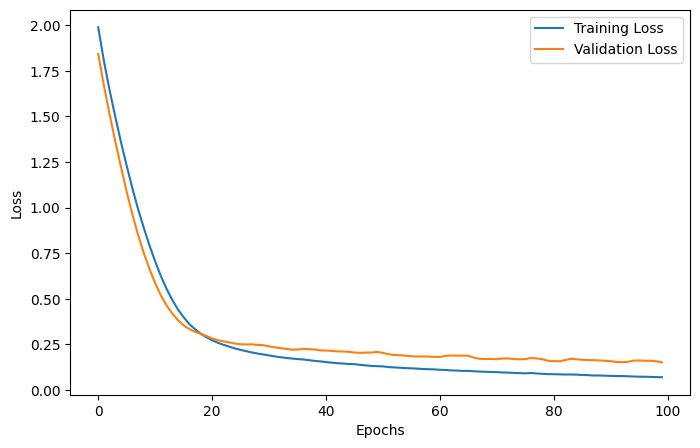

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
test_loss,test_acc=model.evaluate(X_test,y_test)
print(f"Test Accuracy: {test_acc}")
print("test loss:",test_loss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9524 - loss: 0.1517
Test Accuracy: 0.9523809552192688
test loss: 0.1516726166009903


In [ ]:
y_Prob=model.predict(X_test,verbose=1)
print(y_Prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
[[9.95900393e-01 7.84909280e-05 3.88288777e-03 6.95797667e-07
  1.17981755e-04 2.97273255e-06 1.34327611e-05 3.12618886e-06]
 [5.35332540e-04 5.12953147e-06 9.99454618e-01 2.99858220e-06
  1.46348282e-06 6.88323212e-08 1.20070425e-07 4.16886962e-07]
 [1.26667973e-03 9.98732388e-01 2.19727355e-07 1.07236008e-12
  3.70919224e-07 2.21593098e-07 5.16654381e-08 4.21310231e-09]
 [7.71706581e-01 6.00060390e-04 2.26201966e-01 1.07683030e-04
  1.10913301e-03 5.16257569e-05 1.43779951e-04 7.90619015e-05]
 [5.05707085e-01 3.19766223e-05 4.94188875e-01 4.23005940e-06
  6.21097279e-05 8.22922914e-07 3.01667365e-06 1.82930012e-06]]


In [ ]:
y_pred = np.argmax(y_Prob, axis=1)
print(y_pred[:5])

[0 2 1 0 0]


In [ ]:
y_original=y_pred + 1
y_test_original= y_test + 1